<a href="https://colab.research.google.com/github/Matheus-Melo-dos-Santos/DIP-2026.2/blob/main/task_11_kmeans_color_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 11: Automatic Color Segmentation with K-Means

Task 10 used manually selected Hue intervals. Here, K-means automatically finds color groups among the chip pixels.

## 1. Install and import the toolkit

Install before importing `dip_toolkit`.

In [1]:
%pip install -q "git+https://github.com/tfvieira/dip-2026-2.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np

from dip_toolkit import download_course_image

## 2. Load `chips.png`

Downloading...
From: https://drive.google.com/uc?id=12QCGLjlV3odrBXgM3wBq2ME7UzaBxZ4x
To: /content/assets/images/chips.png
100%|██████████| 304k/304k [00:00<00:00, 24.7MB/s]


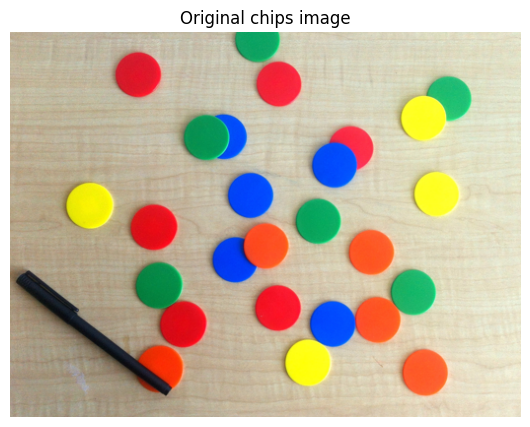

In [3]:
image_path = download_course_image("chips.png")
loaded_image = plt.imread(image_path)

if np.issubdtype(loaded_image.dtype, np.floating):
    rgb_image = np.rint(np.clip(loaded_image[..., :3], 0.0, 1.0) * 255.0).astype(
        np.uint8
    )
else:
    rgb_image = loaded_image[..., :3].astype(np.uint8, copy=True)

plt.figure(figsize=(7, 5))
plt.imshow(rgb_image)
plt.title("Original chips image")
plt.axis("off");

## 3. Provided preprocessing

The background removal step is provided. Pixels with `Saturation > 0.80` are chip pixels, so this task can focus on K-means.

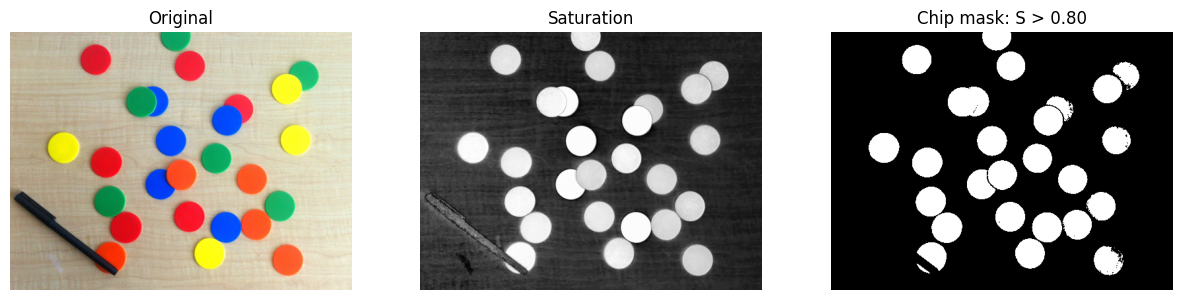

In [4]:
def rgb_to_hsv(image):
    """Converts an RGB uint8 image to HSV float64."""
    if image.ndim != 3 or image.shape[-1] != 3 or image.dtype != np.uint8:
        raise ValueError("image must have shape (H, W, 3) and dtype uint8")
    rgb = image.astype(np.float64) / 255.0
    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    maximum, minimum = np.max(rgb, axis=-1), np.min(rgb, axis=-1)
    delta = maximum - minimum
    hue = np.zeros_like(maximum)
    nonzero = delta > 0.0
    red_maximum = nonzero & (maximum == red)
    green_maximum = nonzero & (maximum == green)
    blue_maximum = nonzero & (maximum == blue)
    hue[red_maximum] = np.mod(
        (green[red_maximum] - blue[red_maximum]) / delta[red_maximum], 6.0
    )
    hue[green_maximum] = (blue[green_maximum] - red[green_maximum]) / delta[
        green_maximum
    ] + 2.0
    hue[blue_maximum] = (red[blue_maximum] - green[blue_maximum]) / delta[
        blue_maximum
    ] + 4.0
    saturation = np.divide(
        delta, maximum, out=np.zeros_like(delta), where=maximum > 0.0
    )
    return np.stack((np.mod(hue * 60.0, 360.0), saturation, maximum), axis=-1)


def create_saturation_mask(hsv, saturation_threshold=0.80):
    """Returns pixels whose Saturation is above the threshold."""
    if hsv.ndim != 3 or hsv.shape[-1] != 3:
        raise ValueError("hsv must have shape (H, W, 3)")
    if not 0.0 <= saturation_threshold <= 1.0:
        raise ValueError("saturation_threshold must be in [0, 1]")
    return hsv[..., 1] > saturation_threshold


hsv_image = rgb_to_hsv(rgb_image)
chip_mask = create_saturation_mask(hsv_image)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(rgb_image)
axes[0].set_title("Original")
axes[1].imshow(hsv_image[..., 1], cmap="gray", vmin=0.0, vmax=1.0)
axes[1].set_title("Saturation")
axes[2].imshow(chip_mask, cmap="gray")
axes[2].set_title("Chip mask: S > 0.80")
for axis in axes:
    axis.axis("off")

## 4. Hue histogram and circular features

Only Hue values inside the chip mask enter clustering. Hue is circular, therefore `[cos(theta), sin(theta)]` keeps values near 0 and 360 degrees close.

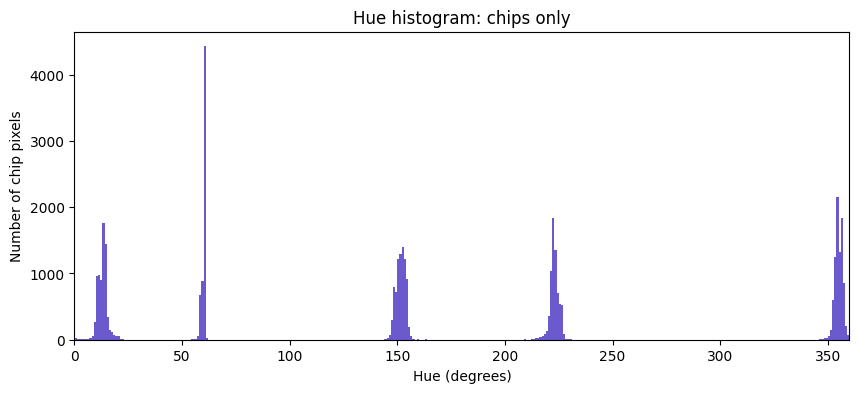

In [5]:
chip_hues = hsv_image[..., 0][chip_mask]

plt.figure(figsize=(10, 4))
plt.hist(chip_hues, bins=360, range=(0.0, 360.0), color="slateblue")
plt.xlim(0.0, 360.0)
plt.xlabel("Hue (degrees)")
plt.ylabel("Number of chip pixels")
plt.title("Hue histogram: chips only")


def hue_to_circular_features(hue_degrees):
    """Converts Hue degrees to two-dimensional circular features."""
    angles = np.deg2rad(hue_degrees)
    return np.column_stack((np.cos(angles), np.sin(angles)))


def circular_centroids_to_hue(centroids):
    """Converts circular centroid coordinates back to Hue degrees."""
    return np.mod(np.rad2deg(np.arctan2(centroids[:, 1], centroids[:, 0])), 360.0)

## 5. Provided deterministic K-means++ initialization

This helper uses a fixed seed and does not modify `features`.

In [6]:
def initialize_centroids(features, k, seed=0):
    """Initializes K-means centroids with deterministic K-means++."""
    if features.ndim != 2 or features.shape[0] == 0:
        raise ValueError("features must have shape (N, D) with N > 0")
    if not 1 <= k <= features.shape[0]:
        raise ValueError("k must satisfy 1 <= k <= number of samples")

    rng = np.random.default_rng(seed)
    chosen_indices = [int(rng.integers(features.shape[0]))]
    while len(chosen_indices) < k:
        chosen = features[chosen_indices]
        distances = np.sum((features[:, None, :] - chosen[None, :, :]) ** 2, axis=2)
        nearest = np.min(distances, axis=1)
        nearest[chosen_indices] = 0.0
        remaining = np.setdiff1d(np.arange(features.shape[0]), chosen_indices)
        total = nearest.sum()
        if total == 0.0:
            next_index = int(rng.choice(remaining))
        else:
            next_index = int(rng.choice(features.shape[0], p=nearest / total))
        chosen_indices.append(next_index)
    return features[chosen_indices].copy()

## 6. Assign clusters

Return the nearest-centroid index for each feature vector. Squared Euclidean distance is sufficient.

In [7]:
def assign_clusters(features, centroids):
    """Assigns each feature vector to its nearest centroid."""
    labels = None

    ### START CODE HERE ###

    distances = np.sum((features[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)

    labels = np.argmin(distances, axis=1)

    ### END CODE HERE ###

    return labels

## 7. Update centroids

Use the mean of each cluster. If a cluster is empty, preserve its previous centroid.

In [8]:
def update_centroids(features, labels, previous_centroids):
    """Updates cluster centroids from their assigned feature vectors."""
    centroids = None

    ### START CODE HERE ###

    k = previous_centroids.shape[0]

    centroids = previous_centroids.copy()

    for i in range(k):
        member_mask = (labels == i)
        if np.any(member_mask):
            centroids[i] = np.mean(features[member_mask], axis=0)

    ### END CODE HERE ###

    return centroids

## 8. Run K-means

Use the provided initializer, alternate assignment and update, and stop when labels do not change or at `max_iterations`. Validate `1 <= k <= N`.

In [9]:
def kmeans(features, k, max_iterations=100):
    """Runs deterministic K-means clustering."""
    labels = None
    centroids = None

    ### START CODE HERE ###

    n_samples = features.shape[0]
    # Validação do contrato: 1 <= k <= N
    if not (1 <= k <= n_samples):
        raise ValueError("k must satisfy 1 <= k <= number of samples")

    centroids = initialize_centroids(features, k, seed=0)

    for _ in range(max_iterations):
        current_labels = assign_clusters(features, centroids)

        if labels is not None and np.array_equal(current_labels, labels):
            break

        labels = current_labels
        centroids = update_centroids(features, labels, centroids)

    # Caso pare na primeira iteração e 'labels' ainda seja None, garantimos sua atribuição
    if labels is None:
        labels = assign_clusters(features, centroids)

    ### END CODE HERE ###

    return labels, centroids

## 9. Reconstruct the segmentation image

Cluster only `hsv[..., 0][chip_mask]`, then rebuild a label image. Background is `0`; chip pixels are `1` through `K`. Cluster IDs are arbitrary.

In [10]:
def segment_chips_kmeans(hsv, chip_mask, k):
    """Segments chip pixels into K color clusters."""
    label_image = None
    centroids = None

    ### START CODE HERE ###

    hue_pixels = hsv[..., 0][chip_mask]

    circular_features = hue_to_circular_features(hue_pixels)

    labels, centroids = kmeans(circular_features, k)

    label_image = np.zeros(hsv.shape[:2], dtype=np.int32)

    label_image[chip_mask] = labels + 1

    ### END CODE HERE ###

    return label_image, centroids

## 10. Deterministic tests

Run this after implementing all four functions.

In [11]:
features = np.array(
    [[0.0, 0.0], [0.2, 0.0], [9.8, 10.0], [10.0, 10.0]], dtype=np.float64
)
centroids = np.array([[0.0, 0.0], [10.0, 10.0]], dtype=np.float64)
features_before = features.copy()
centroids_before = centroids.copy()
labels = assign_clusters(features, centroids)
np.testing.assert_array_equal(labels, np.array([0, 0, 1, 1]))
np.testing.assert_allclose(
    update_centroids(features, labels, centroids), [[0.1, 0.0], [9.9, 10.0]]
)
np.testing.assert_array_equal(features, features_before)
np.testing.assert_array_equal(centroids, centroids_before)

empty_features = np.array([[0.0, 0.0], [1.0, 0.0]])
empty_labels = np.array([0, 0])
previous = np.array([[0.5, 0.0], [10.0, 10.0]])
np.testing.assert_allclose(
    update_centroids(empty_features, empty_labels, previous), previous
)

hues = np.array([359.0, 1.0, 2.0, 118.0, 120.0, 122.0])
circular_features = hue_to_circular_features(hues)
circular_before = circular_features.copy()
circular_labels, circular_centroids = kmeans(circular_features, k=2)
repeat_labels, repeat_centroids = kmeans(circular_features, k=2)
np.testing.assert_array_equal(circular_labels, repeat_labels)
np.testing.assert_allclose(circular_centroids, repeat_centroids)
np.testing.assert_array_equal(circular_features, circular_before)
assert circular_labels[0] == circular_labels[1] == circular_labels[2]
assert circular_labels[3] == circular_labels[4] == circular_labels[5]
assert circular_labels[0] != circular_labels[3]

test_hsv = np.array(
    [[[0.0, 1.0, 1.0], [120.0, 1.0, 1.0]], [[240.0, 1.0, 1.0], [0.0, 0.0, 0.0]]]
)
test_mask = np.array([[True, True], [True, False]])
test_hsv_before = test_hsv.copy()
test_mask_before = test_mask.copy()
label_image, _ = segment_chips_kmeans(test_hsv, test_mask, k=2)
assert label_image.shape == (2, 2) and np.issubdtype(label_image.dtype, np.integer)
assert label_image[1, 1] == 0 and np.all(
    (label_image[test_mask] >= 1) & (label_image[test_mask] <= 2)
)
np.testing.assert_array_equal(test_hsv, test_hsv_before)
np.testing.assert_array_equal(test_mask, test_mask_before)

for invalid_k in (0, 5):
    try:
        kmeans(features, invalid_k)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid k must raise ValueError")

print("Test passed!")

Test passed!


## 11. Result with K = 5 and interactive exploration

Each cluster is displayed using the mean RGB color of its pixels. Change `K` from 2 to 8 to compare the segmentations and Hue representatives.

In [12]:
def colorize_clusters(label_image, rgb):
    """Colors each cluster with the mean RGB color of its pixels."""
    colored = np.zeros_like(rgb)
    for label in range(1, int(label_image.max()) + 1):
        pixels = rgb[label_image == label]
        if pixels.size:
            colored[label_image == label] = np.rint(pixels.mean(axis=0)).astype(
                np.uint8
            )
    return colored


def show_kmeans_result(k):
    label_image, centroids = segment_chips_kmeans(hsv_image, chip_mask, k)
    segmented_rgb = colorize_clusters(label_image, rgb_image)
    representatives = np.sort(circular_centroids_to_hue(centroids))
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(rgb_image)
    axes[0].set_title("Original")
    axes[1].imshow(chip_mask, cmap="gray")
    axes[1].set_title("Chip mask")
    axes[2].imshow(segmented_rgb)
    axes[2].set_title(f"K-means segmentation (K = {k})")
    for axis in axes[:3]:
        axis.axis("off")
    axes[3].hist(chip_hues, bins=360, range=(0.0, 360.0), color="slateblue")
    for hue in representatives:
        axes[3].axvline(hue, color="crimson", linewidth=2)
    axes[3].set(
        xlim=(0.0, 360.0), title="Hue histogram with centroids", xlabel="Hue (degrees)"
    )
    print("Hue representatives (degrees):", representatives.round(1))


k_slider = widgets.IntSlider(
    value=5, min=2, max=8, step=1, description="K:", continuous_update=False
)
widgets.interact(show_kmeans_result, k=k_slider);

interactive(children=(IntSlider(value=5, continuous_update=False, description='K:', max=8, min=2), Output()), …

## Compare with Task 10

Task 10 required manual Hue intervals based on histogram peaks. Here, K-means discovers groups automatically, but `K` must be chosen and cluster IDs have no semantic order.

## Explore

- What happens when `K` is smaller or larger than the real number of colors?
- Why is `K = 5` appropriate for this image?
- Which approach needs more prior knowledge about colors?
- Why is Hue circular? Does K-means guarantee that cluster 1 is red?
- What limitations does K-means have for color segmentation?

Resposta:

* Se K < número de cores reais, um conjunto dos chips vão ser atribuidos a um grupo que não so representa.
* Porque existem 5 cores distintas, valor suficiente para descrever  a situação de forma realista
* A abordagem anterior pela separação manual e o conhecimento prévio da quantidade de cores. Ao usar k-means, o intervalo e a quantidade de cores distintas podem ser obtidos de forma experimental variando k.
* No processo de planificação do cubo de cores, podemos representar a mudança da matiz(Hue) como uma rotação em torno do eixo central. Dessa forma, caracterizamos o matiz por um ângulo e aprensenta essa caracteristica circular. O k-means não garante q a label 1 coincida com o a cor vermelha.

* Caso K seja insuficiente, não consegue separar corretamente os elementos, associado cores erradas a certos elementos pelo conjunto insuficiente de cores para a associação.